# Projet de Machine Learning – Maintenance prédictive (valve hydraulique)
**Machine Learning I – ING2-BDML – EFREI Paris**

**Objectif** : prédire, pour chaque cycle, si la condition de la valve est optimale (= 100 %) ou non.
Les **2 000 premiers cycles** servent à construire le modèle ; les cycles restants forment l'**échantillon de test final**, utilisé une seule fois, à la fin.

**Données** (une ligne = un cycle de 60 s) : `PS2.txt` (pression, 100 Hz), `FS1.txt` (débit, 10 Hz), `profile.txt` (condition des composants, dont la valve).

**Méthodologie** : 1. Prétraitement · 2. Modélisation · 3. Évaluation · 4. Optimisation des hyperparamètres.

# 1. Prétraitement des données

## 1.1 Chargement des données et statistiques descriptives

In [1]:
# 1.1 Chargement des données
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

DATA_DIR = 'data'      # dossier contenant PS2.txt, FS1.txt et profile.txt
N_DEV = 2000           # 2000 premiers cycles : construction du modèle
RANDOM_STATE = 42

# Une ligne = un cycle. Fichiers sans en-tête.
ps2 = pd.read_csv(f'{DATA_DIR}/PS2.txt', sep=r'\s+', header=None)
fs1 = pd.read_csv(f'{DATA_DIR}/FS1.txt', sep=r'\s+', header=None)
profile = pd.read_csv(f'{DATA_DIR}/profile.txt', sep=r'\s+', header=None,
                      names=['Cooler', 'Valve', 'Pump_leakage', 'Accumulator', 'Stable_flag'])

print('PS2     :', ps2.shape, '(cycles x mesures à 100 Hz)')
print('FS1     :', fs1.shape, '(cycles x mesures à 10 Hz)')
print('profile :', profile.shape)
assert len(ps2) == len(fs1) == len(profile), 'Nombre de cycles incohérent entre les fichiers'
profile.head()

PS2     : (2205, 6000) (cycles x mesures à 100 Hz)
FS1     : (2205, 600) (cycles x mesures à 10 Hz)
profile : (2205, 5)


,Cooler,Valve,Pump_leakage,Accumulator,Stable_flag
0,3,100,0,130,1
1,3,100,0,130,1
2,3,100,0,130,1
3,3,100,0,130,1
4,3,100,0,130,1


In [2]:
# 1.1 (suite) Séparation : 2000 premiers cycles (développement) / cycles restants (test final)
ps2_dev, ps2_test = ps2.iloc[:N_DEV], ps2.iloc[N_DEV:]
fs1_dev, fs1_test = fs1.iloc[:N_DEV], fs1.iloc[N_DEV:]
profile_dev, profile_test = profile.iloc[:N_DEV], profile.iloc[N_DEV:]

print('Cycles de développement :', len(profile_dev))
print('Cycles de test final    :', len(profile_test))

Cycles de développement : 2000
Cycles de test final    : 205


In [3]:
# 1.1 (suite) Statistiques descriptives de profile.txt (développement)
print(profile_dev.describe().round(2))

        Cooler    Valve  Pump_leakage  Accumulator  Stable_flag
count  2000.00  2000.00       2000.00      2000.00      2000.00
mean     35.22    90.95          0.67       108.65         0.37
std      39.88    10.67          0.82        16.53         0.48
min       3.00    73.00          0.00        90.00         0.00
25%       3.00    80.00          0.00        90.00         0.00
50%      20.00   100.00          0.00       100.00         0.00
75%     100.00   100.00          1.00       130.00         1.00
max     100.00   100.00          2.00       130.00         1.00


In [4]:
# 1.1 (suite) Statistiques descriptives des signaux bruts (toutes les mesures, développement)
for nom, df in [('PS2 (bar)', ps2_dev), ('FS1 (l/min)', fs1_dev)]:
    v = df.to_numpy().ravel()
    print(f'{nom:12s} min={v.min():8.2f} | moyenne={v.mean():8.2f} | médiane={np.median(v):8.2f} | '
          f'max={v.max():8.2f} | écart-type={v.std():7.2f}')

PS2 (bar)    min=    0.00 | moyenne=  109.39 | médiane=  125.66 | max=  167.74 | écart-type=  48.18
FS1 (l/min)  min=    0.00 | moyenne=    6.16 | médiane=    7.64 | max=   20.48 | écart-type=   3.23


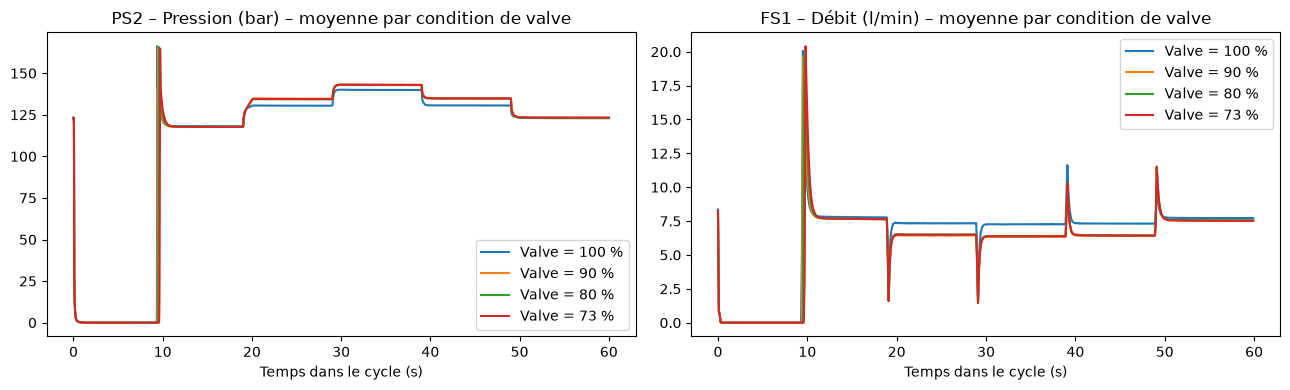

In [5]:
# 1.1 (suite) Allure moyenne d'un cycle selon la condition de la valve
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (nom, df, hz) in zip(axes, [('PS2 – Pression (bar)', ps2_dev, 100), ('FS1 – Débit (l/min)', fs1_dev, 10)]):
    t = np.arange(df.shape[1]) / hz
    for val in sorted(profile_dev['Valve'].unique(), reverse=True):
        masque = (profile_dev['Valve'] == val).to_numpy()
        ax.plot(t, df[masque].mean(axis=0), label=f'Valve = {val} %')
    ax.set_title(nom + ' – moyenne par condition de valve')
    ax.set_xlabel('Temps dans le cycle (s)')
    ax.legend()
plt.tight_layout()
plt.show()

In [6]:
# 1.1 (suite) Résumé de chaque cycle par des statistiques descriptives (une ligne = un cycle)
def extraire_features(df, prefixe):
    X = df.to_numpy(dtype=float)
    f = pd.DataFrame(index=df.index)
    f[f'{prefixe}_mean'] = X.mean(axis=1)
    f[f'{prefixe}_std'] = X.std(axis=1)
    f[f'{prefixe}_min'] = X.min(axis=1)
    f[f'{prefixe}_max'] = X.max(axis=1)
    f[f'{prefixe}_median'] = np.median(X, axis=1)
    f[f'{prefixe}_q25'] = np.percentile(X, 25, axis=1)
    f[f'{prefixe}_q75'] = np.percentile(X, 75, axis=1)
    f[f'{prefixe}_skew'] = stats.skew(X, axis=1)
    f[f'{prefixe}_kurtosis'] = stats.kurtosis(X, axis=1)
    return f

# Calcul cycle par cycle : aucune information du test n'est utilisée pour le développement
features = pd.concat([extraire_features(ps2, 'PS2'), extraire_features(fs1, 'FS1')], axis=1)
X_dev, X_test = features.iloc[:N_DEV], features.iloc[N_DEV:]

print('Tableau de variables :', features.shape, '(cycles x variables)')
X_dev.describe().T.round(3)

Tableau de variables : (2205, 18) (cycles x variables)


,count,mean,std,min,25%,50%,75%,max
PS2_mean,2000.0,109.393,5.235,104.406,106.835,107.558,109.380,131.589
PS2_std,2000.0,47.775,3.432,45.203,46.153,46.639,47.158,59.548
PS2_min,2000.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
PS2_max,2000.0,166.450,0.998,155.040,166.100,166.570,167.020,167.740
PS2_median,2000.0,128.554,3.619,124.445,127.025,127.810,129.875,165.400
PS2_q25,2000.0,117.997,1.715,112.840,116.480,117.930,120.060,120.690
PS2_q75,2000.0,132.728,12.020,125.040,127.645,128.300,130.470,165.560
PS2_skew,2000.0,-1.771,0.146,-1.842,-1.835,-1.830,-1.794,-1.318
PS2_kurtosis,2000.0,1.351,0.305,0.455,1.340,1.477,1.506,1.522
FS1_mean,2000.0,6.161,1.077,2.019,6.376,6.577,6.647,6.723


## 1.2 Gestion des valeurs manquantes et détection des valeurs aberrantes

In [7]:
# 1.2 Valeurs manquantes : comptage
print('Valeurs manquantes PS2      :', int(ps2.isnull().sum().sum()))
print('Valeurs manquantes FS1      :', int(fs1.isnull().sum().sum()))
print('Valeurs manquantes profile  :', int(profile.isnull().sum().sum()))
print('Valeurs manquantes variables :', int(features.isnull().sum().sum()))

Valeurs manquantes PS2      : 0
Valeurs manquantes FS1      : 0
Valeurs manquantes profile  : 0
Valeurs manquantes variables : 0


In [8]:
# 1.2 (suite) Gestion : médiane du développement, uniquement s'il manque des valeurs
if features.isnull().any().any():
    medianes = X_dev.median()
    X_dev, X_test = X_dev.fillna(medianes), X_test.fillna(medianes)
    print('-> Valeurs manquantes remplacées par la médiane du développement.')
else:
    print('-> Aucune valeur manquante : aucun traitement nécessaire.')

-> Aucune valeur manquante : aucun traitement nécessaire.


In [9]:
# 1.2 (suite) Valeurs aberrantes : règle de l'IQR, bornes calculées sur le développement
Q1, Q3 = X_dev.quantile(0.25), X_dev.quantile(0.75)
IQR = Q3 - Q1
aberrant = (X_dev < Q1 - 1.5 * IQR) | (X_dev > Q3 + 1.5 * IQR)

taux = (aberrant.mean() * 100).sort_values(ascending=False)
print('Variables avec le plus de valeurs aberrantes (% des cycles) :')
print(taux.head(8).round(1))
print(f"\nCycles ayant au moins une variable aberrante : {aberrant.any(axis=1).mean() * 100:.1f} %")
print('\nPart de cycles avec >= 1 valeur aberrante, selon la condition de la valve (%) :')
print((aberrant.any(axis=1).groupby(profile_dev['Valve']).mean() * 100).round(1))

Variables avec le plus de valeurs aberrantes (% des cycles) :
FS1_std         13.2
PS2_mean        12.0
PS2_std         12.0
FS1_mean        12.0
PS2_skew        12.0
PS2_kurtosis    12.0
FS1_q25         12.0
FS1_skew        12.0
dtype: float64

Cycles ayant au moins une variable aberrante : 19.7 %

Part de cycles avec >= 1 valeur aberrante, selon la condition de la valve (%) :
Valve
73     23.4
80     23.3
90     26.1
100    15.5
dtype: float64


## 1.3 Encodage des variables catégorielles

In [10]:
# 1.3 Encodage des variables catégorielles : y en a-t-il ?
print('Types des variables explicatives :')
print(X_dev.dtypes.value_counts())
print('\nValeurs possibles de la condition de la valve :', sorted(int(v) for v in profile_dev['Valve'].unique()))

Types des variables explicatives :
float64    18
Name: count, dtype: int64

Valeurs possibles de la condition de la valve : [73, 80, 90, 100]


## 1.4 Transformation du problème en classification binaire

In [11]:
# 1.4 Cible binaire : 1 = valve optimale (100 %), 0 = non optimale (90, 80 ou 73 %)
y_all = (profile['Valve'] == 100).astype(int)
y_dev, y_test = y_all.iloc[:N_DEV], y_all.iloc[N_DEV:]

print(pd.crosstab(profile_dev['Valve'], y_dev, rownames=['Valve (%)'], colnames=['Cible binaire']))

Cible binaire    0     1
Valve (%)               
73             320     0
80             318     0
90             310     0
100              0  1052


## 1.5 Analyse de la distribution des classes

                  Effectif  Proportion
0 – non optimale       948       0.474
1 – optimale          1052       0.526


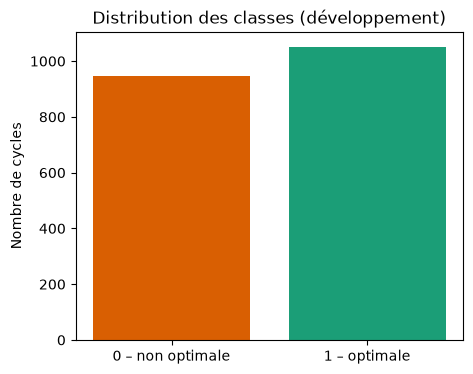

In [12]:
# 1.5 Équilibre des classes (développement)
comptes = y_dev.value_counts().sort_index()
parts = y_dev.value_counts(normalize=True).sort_index()
print(pd.DataFrame({'Effectif': comptes.values, 'Proportion': parts.round(3).values},
                   index=['0 – non optimale', '1 – optimale']))

plt.figure(figsize=(5, 4))
plt.bar(['0 – non optimale', '1 – optimale'], comptes.values, color=['#d95f02', '#1b9e77'])
plt.ylabel('Nombre de cycles')
plt.title('Distribution des classes (développement)')
plt.show()

In [13]:
# 1.5 (suite) Part de valves optimales : développement et test final
print(f'Part de valves optimales : développement = {y_dev.mean():.3f} | test final = {y_test.mean():.3f}')

Part de valves optimales : développement = 0.526 | test final = 0.356


## 1.6 Analyse des corrélations entre les variables

In [14]:
# 1.6 Corrélations entre variables et avec la cible
corr = X_dev.corr()
corr_cible = X_dev.apply(lambda col: col.corr(y_dev)).dropna().sort_values(key=abs, ascending=False)

print('Les 10 variables les plus corrélées à la cible (valve optimale) :')
print(corr_cible.head(10).round(3))

paires = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().dropna()
fortes = paires[paires.abs() > 0.95].sort_values(key=abs, ascending=False)
print(f'\nPaires de variables fortement corrélées (|r| > 0.95) : {len(fortes)} sur {len(paires)}')
print(fortes.head(10).round(3))

Les 10 variables les plus corrélées à la cible (valve optimale) :
PS2_kurtosis    0.343
PS2_skew       -0.270
FS1_skew       -0.259
FS1_mean        0.231
PS2_std        -0.225
FS1_q25         0.210
FS1_median      0.207
FS1_q75         0.186
FS1_std        -0.185
PS2_q75        -0.175
dtype: float64

Paires de variables fortement corrélées (|r| > 0.95) : 33 sur 136
PS2_skew    PS2_kurtosis   -0.994
FS1_mean    FS1_skew       -0.994
PS2_std     PS2_q75         0.994
FS1_mean    FS1_q25         0.993
            FS1_median      0.989
PS2_q75     FS1_q25        -0.989
PS2_skew    FS1_q25        -0.989
PS2_mean    PS2_std         0.988
FS1_q25     FS1_skew       -0.987
FS1_median  FS1_q25         0.983
dtype: float64


## 1.7 Visualisations

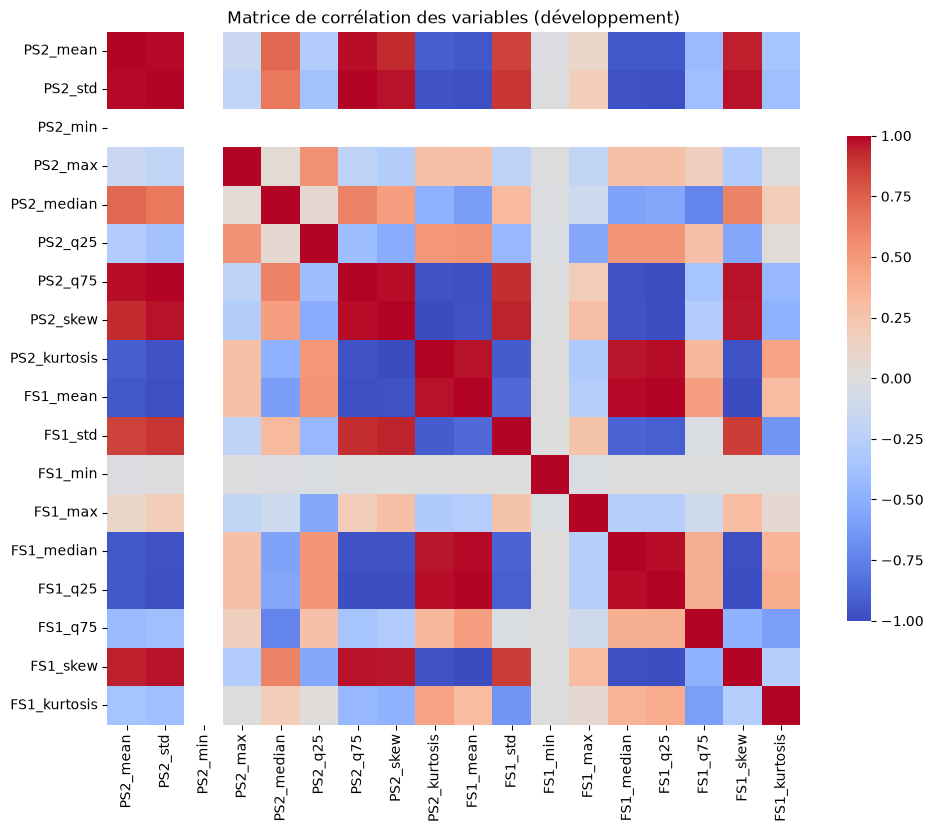

In [15]:
# 1.7 Matrice de corrélation
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.7})
plt.title('Matrice de corrélation des variables (développement)')
plt.show()

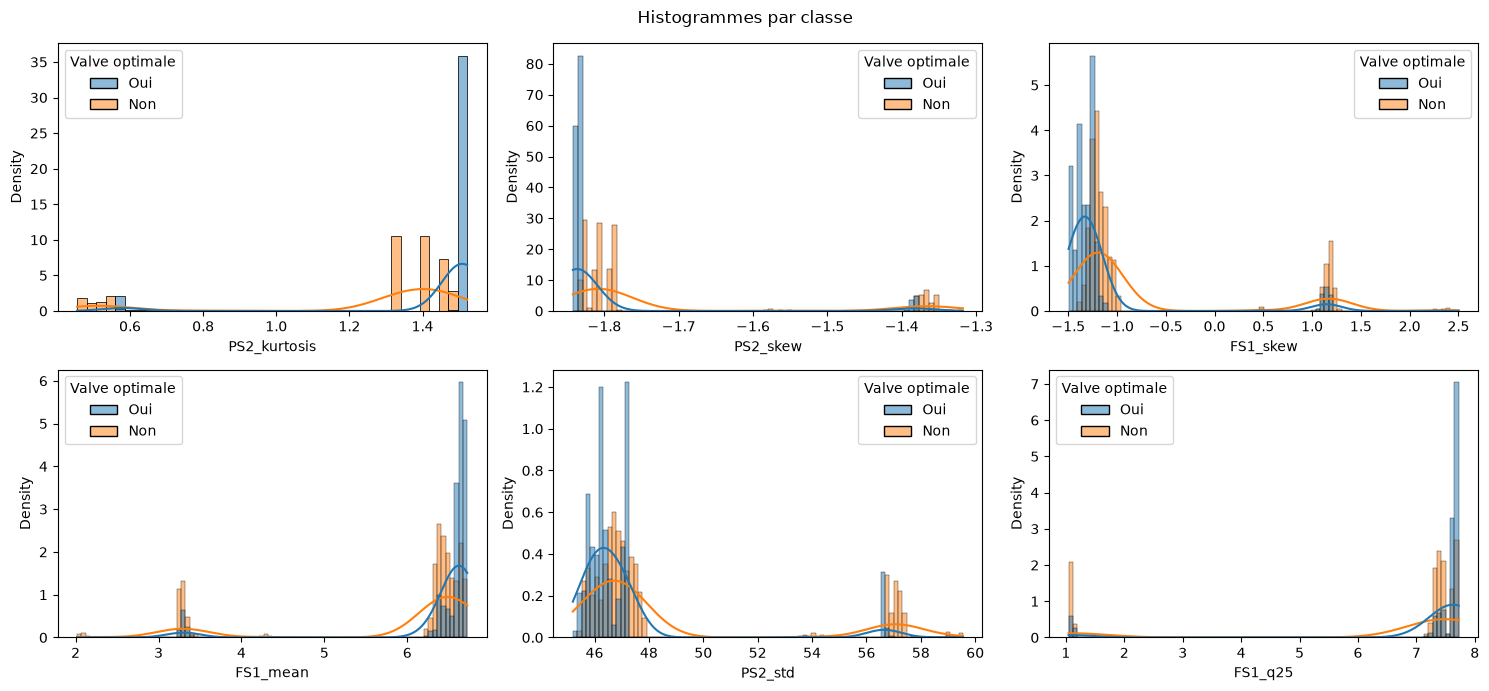

In [16]:
# 1.7 (suite) Histogrammes des 6 variables les plus corrélées à la cible
top6 = corr_cible.index[:6].tolist()
donnees = X_dev[top6].copy()
donnees['Valve optimale'] = y_dev.map({0: 'Non', 1: 'Oui'})

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), top6):
    sns.histplot(data=donnees, x=col, hue='Valve optimale', kde=True, stat='density', common_norm=False, ax=ax)
fig.suptitle('Histogrammes par classe')
plt.tight_layout()
plt.show()

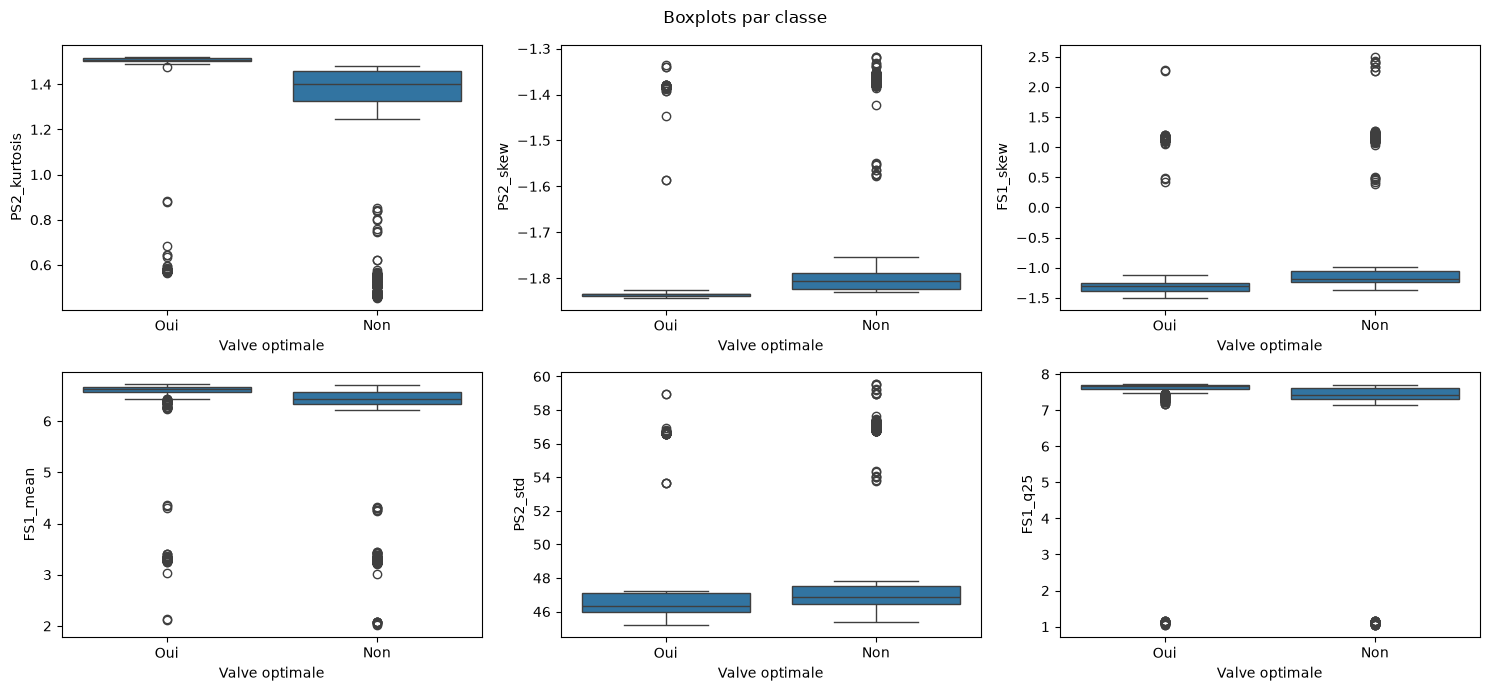

In [17]:
# 1.7 (suite) Boxplots des 6 variables les plus corrélées à la cible
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), top6):
    sns.boxplot(data=donnees, x='Valve optimale', y=col, ax=ax)
fig.suptitle('Boxplots par classe')
plt.tight_layout()
plt.show()

## 1.8 Utilisation de méthodes de sélection de variables (Features selection)

In [18]:
# 1.8 Sélection de variables : filtre de colinéarité, puis trois critères de pertinence
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

SEUIL_CORR = 0.95
K_FEATURES = 8

# a) Variables constantes écartées, puis filtre de colinéarité : parmi des variables corrélées à plus de 0,95, on garde la plus liée à la cible
constantes = [c for c in X_dev.columns if X_dev[c].nunique() <= 2]      # variables constantes ou quasi constantes
gardees = []
for feat in corr_cible.index:
    if feat in constantes:
        continue
    if all(abs(corr.loc[feat, g]) <= SEUIL_CORR for g in gardees):
        gardees.append(feat)
print(f'Variables de départ : {X_dev.shape[1]} | constantes : {constantes} | après filtre de colinéarité : {len(gardees)}')

Variables de départ : 18 | constantes : ['PS2_min', 'FS1_min'] | après filtre de colinéarité : 9


In [19]:
# 1.8 (suite) Scores de pertinence : ANOVA (F), information mutuelle, importance d'une forêt aléatoire
Xs = X_dev[gardees]
f_scores, _ = f_classif(Xs, y_dev)
mi_scores = mutual_info_classif(Xs, y_dev, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(Xs, y_dev)

scores = pd.DataFrame({'ANOVA_F': f_scores, 'Info_mutuelle': mi_scores,
                       'RF_importance': rf.feature_importances_}, index=gardees)

# Agrégation par rang moyen (rang 1 = meilleure variable)
scores['Rang_moyen'] = scores.rank(ascending=False).mean(axis=1)
scores = scores.sort_values('Rang_moyen')
print(scores.round(4))

               ANOVA_F  Info_mutuelle  RF_importance  Rang_moyen
PS2_kurtosis  266.3891         0.6786         0.6515      1.0000
FS1_q75        71.3112         0.2343         0.1376      2.3333
PS2_mean       37.3843         0.3187         0.0564      3.6667
FS1_std        70.6805         0.1802         0.0795      4.0000
PS2_q25        26.5242         0.1944         0.0228      5.3333
PS2_median     14.5911         0.1856         0.0151      6.3333
FS1_max        45.0421         0.0436         0.0083      7.0000
FS1_kurtosis    1.2227         0.0877         0.0249      7.0000
PS2_max        11.6034         0.0780         0.0039      8.3333


8 variables retenues :
['PS2_kurtosis', 'FS1_q75', 'PS2_mean', 'FS1_std', 'PS2_q25', 'PS2_median', 'FS1_max', 'FS1_kurtosis']


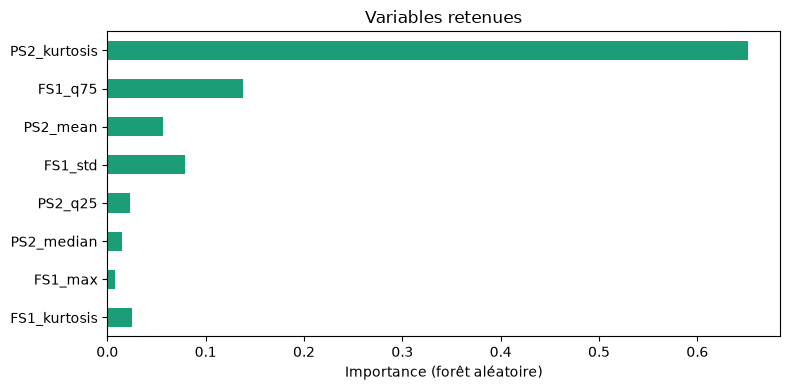

X_dev_sel : (2000, 8) | X_test_sel : (205, 8)


In [20]:
# 1.8 (suite) Variables retenues et jeux de données prêts pour l'étape 2
selected_features = scores.index[:K_FEATURES].tolist()
print(f'{len(selected_features)} variables retenues :')
print(selected_features)

plt.figure(figsize=(8, 4))
scores.loc[selected_features, 'RF_importance'][::-1].plot.barh(color='#1b9e77')
plt.xlabel('Importance (forêt aléatoire)')
plt.title('Variables retenues')
plt.tight_layout()
plt.show()

# Mêmes colonnes pour le test final (aucune statistique du test n'est utilisée)
X_dev_sel, X_test_sel = X_dev[selected_features], X_test[selected_features]
print('X_dev_sel :', X_dev_sel.shape, '| X_test_sel :', X_test_sel.shape)

# 2. Modélisation et évaluation

Cette étape entraîne un modèle de chaque famille demandée, à partir des variables retenues en 1.8 (`X_dev_sel`).

**Protocole.** Pour comparer les modèles **sans toucher au test final**, les 2 000 cycles de développement sont séparés en **entraînement (environ 80 %)** et **validation (environ 20 %)**. Le découpage se fait **par blocs de conditions** et non au hasard : dans le fichier, des cycles consécutifs ont exactement les mêmes conditions de fonctionnement et sont quasi identiques. Un découpage aléatoire placerait des « quasi-doublons » dans l'entraînement et dans la validation, ce qui gonflerait artificiellement les scores (fuite de données). Les hyperparamètres restent simples : valeurs par défaut de scikit-learn, avec une profondeur limitée pour l'arbre et la forêt afin de contrôler le sur-apprentissage. Ils seront optimisés à l'étape 4. Les modèles sensibles aux échelles (régression logistique, k-NN, Naive Bayes, SVM) sont placés dans un `Pipeline` avec un `StandardScaler`, ajusté sur l'entraînement uniquement.

## 2.1 Régression logistique

In [21]:
# 2.1 Régression logistique – préparation : jeux d'entraînement / validation (découpage par blocs de conditions)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Des cycles consécutifs ont les mêmes conditions (refroidisseur, fuite de pompe, accumulateur) : ils sont quasi identiques.
# On forme donc des blocs avec ces trois colonnes, qui servent UNIQUEMENT à découper, jamais comme variables explicatives.
groupes = profile_dev[['Cooler', 'Pump_leakage', 'Accumulator']].astype(str).agg('-'.join, axis=1).to_numpy()

# 5 plis stratifiés qui gardent chaque bloc entier du même côté ; le 1er pli sert de validation (environ 20 %)
cv_blocs = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
plis = list(cv_blocs.split(X_dev_sel, y_dev, groupes))
idx_tr, idx_val = plis[0]
X_tr, X_val = X_dev_sel.iloc[idx_tr], X_dev_sel.iloc[idx_val]
y_tr, y_val = y_dev.iloc[idx_tr], y_dev.iloc[idx_val]

assert not set(groupes[idx_tr]) & set(groupes[idx_val]), 'Un bloc ne doit pas être des deux côtés'
print('Entraînement :', X_tr.shape, '| Validation :', X_val.shape)
print('Part de valves optimales : entraînement = %.3f | validation = %.3f' % (y_tr.mean(), y_val.mean()))

modeles = {}      # modèles entraînés

def entrainer(nom, modele):
    """Entraîne le modèle sur l'entraînement et affiche l'accuracy d'entraînement et de validation."""
    modele.fit(X_tr, y_tr)
    modeles[nom] = modele
    print(f'{nom:28s} accuracy entraînement = {modele.score(X_tr, y_tr):.3f} | validation = {modele.score(X_val, y_val):.3f}')
    return modele

Entraînement : (1544, 8) | Validation : (456, 8)
Part de valves optimales : entraînement = 0.503 | validation = 0.605


In [22]:
# 2.1 Régression logistique
from sklearn.linear_model import LogisticRegression

entrainer('Régression logistique',
          make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)))

Régression logistique        accuracy entraînement = 0.955 | validation = 0.794


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['PS2_kurtosis','FS1_q75','PS2_mean',...,'PS2_median','FS1_max', 'FS1_kurtosis']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [23]:
# 2.1 (suite) Coefficients du modèle (variables standardisées : comparables entre eux)
coef = pd.Series(modeles['Régression logistique'][-1].coef_[0], index=X_tr.columns).sort_values(key=abs, ascending=False)
print(coef.round(3))
print('Intercept :', round(float(modeles['Régression logistique'][-1].intercept_[0]), 3))

PS2_kurtosis    11.083
PS2_mean         9.164
PS2_q25         -2.531
FS1_kurtosis    -2.466
FS1_std         -1.202
FS1_max          0.878
PS2_median      -0.548
FS1_q75          0.161
dtype: float64
Intercept : -0.361


## 2.2 k-NN

In [24]:
# 2.2 k-NN (variables standardisées : méthode basée sur des distances)
from sklearn.neighbors import KNeighborsClassifier

entrainer('k-NN (k=5)', make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)))

k-NN (k=5)                   accuracy entraînement = 0.978 | validation = 0.732


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['PS2_kurtosis','FS1_q75','PS2_mean',...,'PS2_median','FS1_max', 'FS1_kurtosis']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 2.3 Arbre de décision

In [25]:
# 2.3 Arbre de décision (profondeur limitée à 5 pour contrôler le sur-apprentissage)
from sklearn.tree import DecisionTreeClassifier, plot_tree

entrainer('Arbre de décision', DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=RANDOM_STATE))

Arbre de décision            accuracy entraînement = 0.999 | validation = 0.998


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

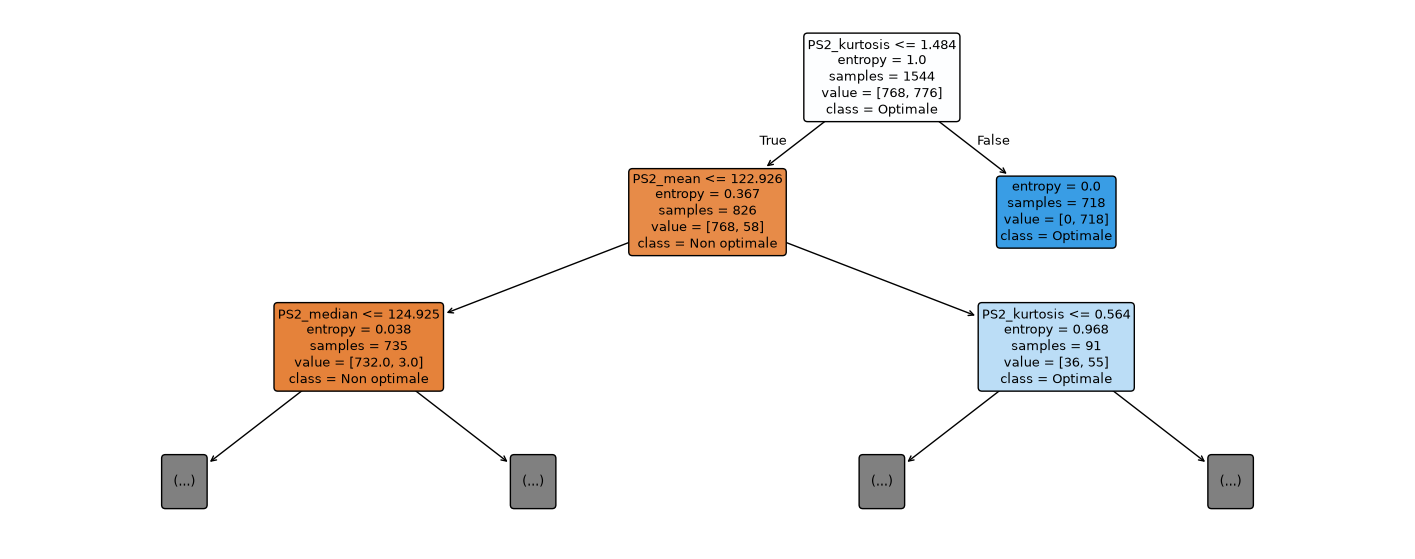

In [26]:
# 2.3 (suite) Visualisation des premiers niveaux de l'arbre
plt.figure(figsize=(18, 7))
plot_tree(modeles['Arbre de décision'], max_depth=2, feature_names=list(X_tr.columns),
          class_names=['Non optimale', 'Optimale'], filled=True, rounded=True, fontsize=9)
plt.show()

## 2.4 Naive Bayes

In [27]:
# 2.4 Naive Bayes gaussien (standardisation : le lissage de variance de scikit-learn dépend de l'échelle)
from sklearn.naive_bayes import GaussianNB

entrainer('Naive Bayes', make_pipeline(StandardScaler(), GaussianNB()))

Naive Bayes                  accuracy entraînement = 0.567 | validation = 0.333


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('gaussiannb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['PS2_kurtosis','FS1_q75','PS2_mean',...,'PS2_median','FS1_max', 'FS1_kurtosis']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 2.5 SVM

In [28]:
# 2.5 SVM linéaire et SVM à noyau gaussien (RBF), variables standardisées
from sklearn.svm import SVC

entrainer('SVM linéaire', make_pipeline(StandardScaler(), SVC(kernel='linear', random_state=RANDOM_STATE)))
entrainer('SVM RBF', make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=RANDOM_STATE)))

SVM linéaire                 accuracy entraînement = 0.989 | validation = 0.991
SVM RBF                      accuracy entraînement = 0.951 | validation = 0.978


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['PS2_kurtosis','FS1_q75','PS2_mean',...,'PS2_median','FS1_max', 'FS1_kurtosis']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 2.6 Ensemble learning

In [29]:
# 2.6 Ensemble learning : bagging (forêt aléatoire) et boosting (gradient boosting)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

entrainer('Forêt aléatoire', RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1))
entrainer('Gradient Boosting', GradientBoostingClassifier(random_state=RANDOM_STATE))

Forêt aléatoire              accuracy entraînement = 1.000 | validation = 0.998
Gradient Boosting            accuracy entraînement = 1.000 | validation = 1.000


,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

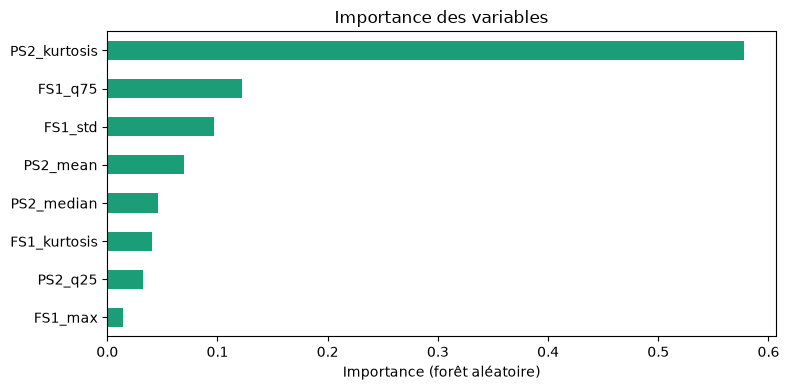

In [30]:
# 2.6 (suite) Importance des variables selon la forêt aléatoire
imp = pd.Series(modeles['Forêt aléatoire'].feature_importances_, index=X_tr.columns).sort_values()

plt.figure(figsize=(8, 4))
imp.plot.barh(color='#1b9e77')
plt.xlabel('Importance (forêt aléatoire)')
plt.title('Importance des variables')
plt.tight_layout()
plt.show()

## 2.7 Justification du choix des modèles

In [31]:
# 2.7 Caractéristiques des données qui guident le choix des modèles
n = X_dev_sel.shape[1]
corr_sel = X_dev_sel.corr().abs().where(~np.eye(n, dtype=bool), 0)

resume = pd.DataFrame({'Asymétrie': X_dev_sel.skew(),
                       'Kurtosis': X_dev_sel.kurt(),
                       'Min': X_dev_sel.min(),
                       'Max': X_dev_sel.max(),
                       '|r| max avec une autre variable': corr_sel.max()})
print(resume.round(2))

etendues = X_dev_sel.max() - X_dev_sel.min()
print(f'\nRapport entre la plus grande et la plus petite étendue : {etendues.max() / etendues.min():.1f}')

              Asymétrie  Kurtosis     Min     Max  \
PS2_kurtosis      -2.19      3.16    0.46    1.52   
FS1_q75          -11.17    138.85    1.15    7.95   
PS2_mean           2.17      3.53  104.41  131.59   
FS1_std            2.22      3.61    2.66    3.74   
PS2_q25            0.16     -1.15  112.84  120.69   
PS2_median         6.64     63.71  124.44  165.40   
FS1_max           -1.25      0.42   18.70   20.48   
FS1_kurtosis       3.46     38.19   -0.35    7.66   

              |r| max avec une autre variable  
PS2_kurtosis                             0.92  
FS1_q75                                  0.74  
PS2_mean                                 0.92  
FS1_std                                  0.92  
PS2_q25                                  0.55  
PS2_median                               0.74  
FS1_max                                  0.55  
FS1_kurtosis                             0.65  

Rapport entre la plus grande et la plus petite étendue : 38.4


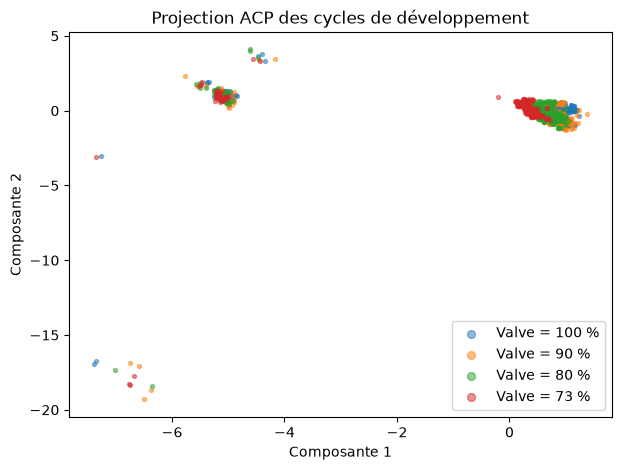

In [32]:
# 2.7 (suite) La classe « non optimale » regroupe trois états de valve : projection en 2 dimensions (ACP)
from sklearn.decomposition import PCA

Z = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(StandardScaler().fit_transform(X_dev_sel))

plt.figure(figsize=(7, 5))
for val in sorted(profile_dev['Valve'].unique(), reverse=True):
    m = (profile_dev['Valve'] == val).to_numpy()
    plt.scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, label=f'Valve = {val} %')
plt.xlabel('Composante 1')
plt.ylabel('Composante 2')
plt.title('Projection ACP des cycles de développement')
plt.legend(markerscale=2)
plt.show()

### Propriétés théoriques (linéaire vs non linéaire)

| Modèle | Frontière de décision | Hypothèses / propriétés | Limites |
|---|---|---|---|
| **Régression logistique** | **Linéaire** | Variables peu redondantes, échelles comparables | Fort biais si les classes ne sont pas séparables linéairement |
| **k-NN** | **Non linéaire**, locale | Non paramétrique ; repose sur les distances | Sensible aux échelles, aux variables inutiles et au bruit |
| **Arbre de décision** | **Non linéaire**, par morceaux | Aucune hypothèse de distribution ; insensible aux échelles | Variance élevée si la profondeur n'est pas limitée |
| **Naive Bayes** | Quadratique/linéaire (génératif) | Variables **indépendantes** et **gaussiennes** sachant la classe | Hypothèses fortes, souvent violées |
| **SVM linéaire** | **Linéaire** (marge maximale) | Standardisation nécessaire | Limité aux frontières linéaires |
| **SVM RBF** | **Non linéaire** (noyau gaussien) | Standardisation ; $C$ et $\gamma$ à régler | Réglage délicat, peu interprétable |
| **Forêt aléatoire** (bagging) | **Non linéaire** | Moyenne d'arbres décorrélés | Moins interprétable qu'un arbre seul |
| **Gradient Boosting** (boosting) | **Non linéaire** | Arbres construits séquentiellement | Sensible au bruit et au sur-apprentissage |

### Adaptabilité aux données du projet

1. **Variables continues, d'échelles différentes** (pression, débit, formes de signal) : la standardisation est nécessaire pour la régression logistique, le k-NN, le SVM et le Naive Bayes. Les arbres et leurs ensembles n'en ont pas besoin. Le rapport entre les étendues (cellule 2.7) le montre.
2. **Variables corrélées entre elles** : toutes résument les mêmes signaux. L'hypothèse d'indépendance du Naive Bayes est donc violée, et les coefficients de la régression logistique sont moins stables. Les forêts y sont robustes.
3. **Distributions non gaussiennes, bruit et valeurs aberrantes** : l'asymétrie et le kurtosis (cellule 2.7) indiquent si l'hypothèse gaussienne du Naive Bayes est acceptable. Les valeurs aberrantes de l'étape 1.2 sont conservées : les méthodes robustes (arbres, forêts, SVM) les supportent mieux.
4. **Classe « non optimale » hétérogène** : elle regroupe trois états de valve (90, 80, 73 %). Une seule loi gaussienne ou une seule frontière linéaire la décrit mal. Les modèles non linéaires (k-NN, arbre, SVM RBF, ensembles) sont plus adaptés. L'ACP ci-dessus montre si ces états forment des groupes distincts.
5. **Taille de l'échantillon (2 000 cycles) et dimension faible (≤ 8 variables)** : assez de données pour des modèles de capacité moyenne, sans justifier un modèle très complexe.

### Conclusion de l'étape 2

On garde huit modèles pour l'évaluation : deux modèles **linéaires** (régression logistique, SVM linéaire) comme références, trois modèles **non linéaires** simples (k-NN, arbre, SVM RBF), un modèle **probabiliste** (Naive Bayes) pour mesurer le coût de l'hypothèse d'indépendance, et deux **ensembles** (forêt, boosting) pour réduire variance et biais. Leur comparaison chiffrée est faite à l'étape 3.

# 3. Évaluation des modèles

Tous les modèles sont évalués sur le **jeu de validation** (environ 20 % des cycles de développement, issus de blocs de conditions absents de l'entraînement). Le **test final** (205 cycles) reste réservé : il sera utilisé une seule fois, à la fin de l'étape 4, pour le modèle optimisé.

## 3.1 Métriques : accuracy, précision, rappel, F1-score

In [33]:
# 3.1 Accuracy, précision, rappel et F1-score sur le jeu de validation (classe positive = valve optimale)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)

lignes = {}
for nom, m in modeles.items():
    y_pred = m.predict(X_val)
    lignes[nom] = {'Accuracy': accuracy_score(y_val, y_pred),
                   'Précision': precision_score(y_val, y_pred),
                   'Rappel': recall_score(y_val, y_pred),
                   'F1': f1_score(y_val, y_pred)}
metriques = pd.DataFrame(lignes).T
metriques.sort_values('F1', ascending=False).round(3)

,Accuracy,Précision,Rappel,F1
Gradient Boosting,1.000,1.000,1.000,1.000
Arbre de décision,0.998,1.000,0.996,0.998
Forêt aléatoire,0.998,1.000,0.996,0.998
SVM linéaire,0.991,1.000,0.986,0.993
SVM RBF,0.978,1.000,0.964,0.982
Régression logistique,0.794,0.974,0.678,0.799
k-NN (k=5),0.732,0.938,0.598,0.730
Naive Bayes,0.333,0.450,0.460,0.455


## 3.2 Matrice de confusion

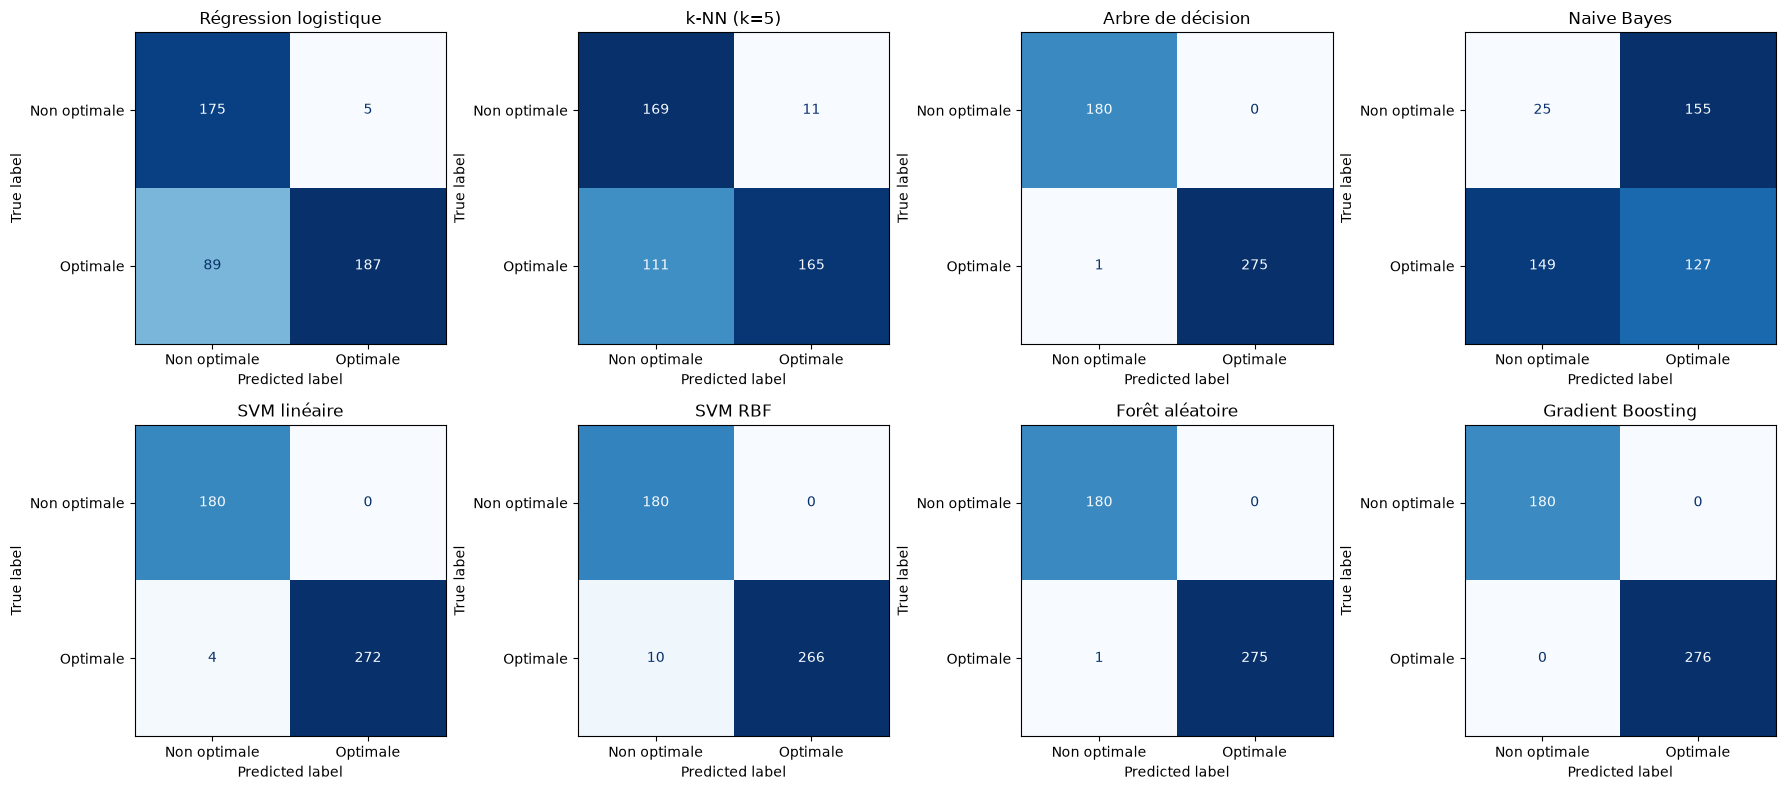

In [34]:
# 3.2 Matrices de confusion (jeu de validation)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (nom, m) in zip(axes.ravel(), modeles.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_val, y_val, display_labels=['Non optimale', 'Optimale'],
                                          cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

In [35]:
# 3.2 (suite) Types d'erreurs de chaque modèle
erreurs = {}
for nom, m in modeles.items():
    tn, fp, fn, tp = confusion_matrix(y_val, m.predict(X_val)).ravel()
    erreurs[nom] = {'Vrais négatifs': tn, 'Faux positifs (non optimale prédite optimale)': fp,
                    'Faux négatifs (optimale prédite non optimale)': fn, 'Vrais positifs': tp}
pd.DataFrame(erreurs).T

,Vrais négatifs,Faux positifs (non optimale prédite optimale),Faux négatifs (optimale prédite non optimale),Vrais positifs
Régression logistique,175,5,89,187
k-NN (k=5),169,11,111,165
Arbre de décision,180,0,1,275
Naive Bayes,25,155,149,127
SVM linéaire,180,0,4,272
SVM RBF,180,0,10,266
Forêt aléatoire,180,0,1,275
Gradient Boosting,180,0,0,276


## 3.3 Courbe ROC et AUC

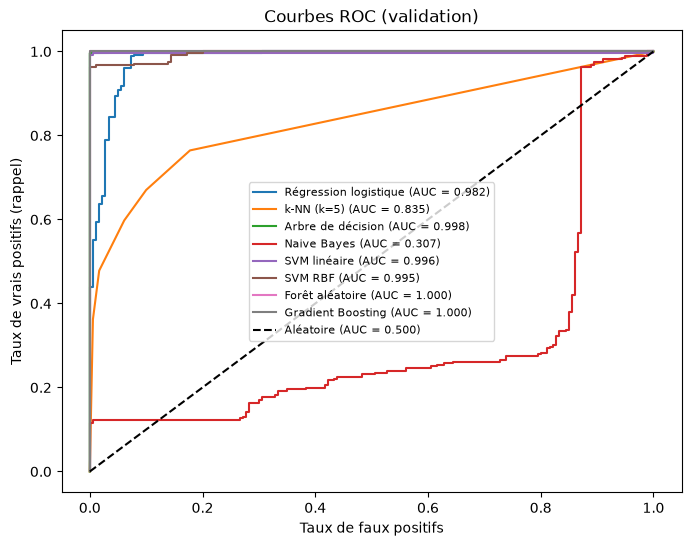

In [36]:
# 3.3 Courbes ROC et AUC (jeu de validation)
def scores_modele(modele, X):
    """Probabilité de la classe 1 si disponible, sinon score de décision (SVM)."""
    if hasattr(modele, 'predict_proba'):
        return modele.predict_proba(X)[:, 1]
    return modele.decision_function(X)

plt.figure(figsize=(8, 6))
auc = {}
for nom, m in modeles.items():
    s = scores_modele(m, X_val)
    fpr, tpr, _ = roc_curve(y_val, s)
    auc[nom] = roc_auc_score(y_val, s)
    plt.plot(fpr, tpr, label=f'{nom} (AUC = {auc[nom]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aléatoire (AUC = 0.500)')
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs (rappel)')
plt.title('Courbes ROC (validation)')
plt.legend(fontsize=8)
plt.show()

## 3.4 Comparaison des performances et interprétation des résultats

                       Accuracy  Précision  Rappel     F1    AUC
Gradient Boosting         1.000      1.000   1.000  1.000  1.000
Arbre de décision         0.998      1.000   0.996  0.998  0.998
Forêt aléatoire           0.998      1.000   0.996  0.998  1.000
SVM linéaire              0.991      1.000   0.986  0.993  0.996
SVM RBF                   0.978      1.000   0.964  0.982  0.995
Régression logistique     0.794      0.974   0.678  0.799  0.982
k-NN (k=5)                0.732      0.938   0.598  0.730  0.835
Naive Bayes               0.333      0.450   0.460  0.455  0.307


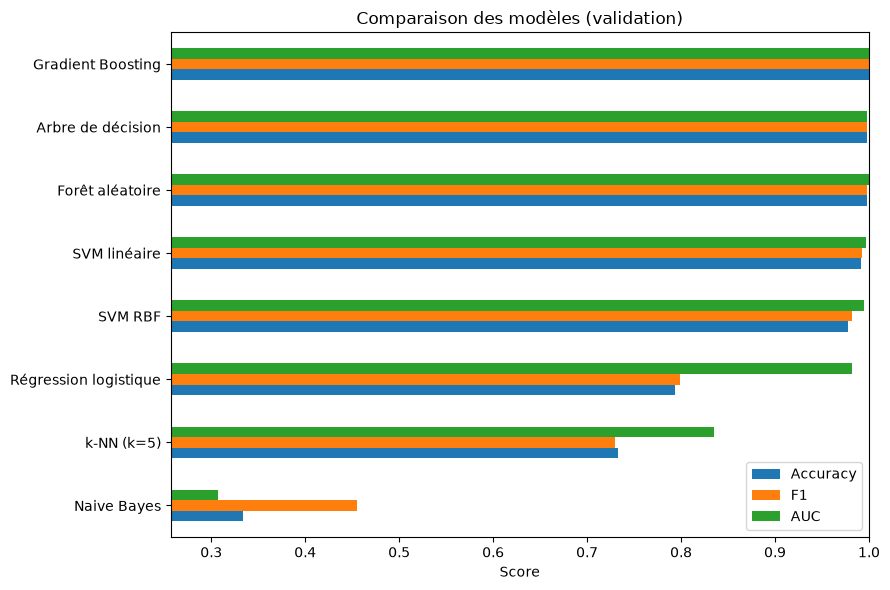

In [37]:
# 3.4 Tableau comparatif (jeu de validation), trié par F1-score
comparaison = metriques.copy()
comparaison['AUC'] = pd.Series(auc)
comparaison = comparaison.sort_values('F1', ascending=False)
print(comparaison.round(3))

comparaison[['Accuracy', 'F1', 'AUC']].iloc[::-1].plot.barh(figsize=(9, 6))
plt.xlabel('Score')
plt.title('Comparaison des modèles (validation)')
plt.xlim(max(0, comparaison[['Accuracy', 'F1', 'AUC']].min().min() - 0.05), 1.0)
plt.tight_layout()
plt.show()

**Comment lire les résultats**
- **Accuracy** : part de cycles bien classés (les classes sont quasi équilibrées, donc elle est interprétable).
- **Précision** : parmi les cycles prédits « optimale », part qui l'est vraiment. Une précision faible signifie que des valves dégradées passent pour optimales (risque pour la maintenance).
- **Rappel** : parmi les valves réellement optimales, part détectée.
- **F1** : moyenne harmonique de la précision et du rappel.
- **AUC** : capacité du modèle à classer une valve optimale au-dessus d'une valve non optimale, quel que soit le seuil (0,5 = hasard, 1 = parfait).

L'interprétation chiffrée (quelle famille domine, quels types d'erreurs, écart entre modèles linéaires et non linéaires) se fait avec les résultats obtenus.

## 3.5 Identification du modèle le plus performant (compromis biais / variance)

In [38]:
# 3.5 Biais et variance : accuracy d'entraînement vs validation, et stabilité en validation croisée par blocs (5 plis)
from sklearn.model_selection import cross_val_score

lignes = {}
for nom, m in modeles.items():
    acc_tr, acc_val = m.score(X_tr, y_tr), m.score(X_val, y_val)
    cv_scores = cross_val_score(m, X_dev_sel, y_dev, cv=plis, scoring='accuracy')
    lignes[nom] = {'Accuracy (train)': acc_tr, 'Accuracy (validation)': acc_val,
                   'Écart train - validation': acc_tr - acc_val,
                   'CV moyenne (5 plis)': cv_scores.mean(), 'CV écart-type': cv_scores.std()}
bv = pd.DataFrame(lignes).T

def diagnostic(r):
    if r['Accuracy (train)'] < 0.80:
        return 'Biais élevé (sous-apprentissage)'
    if r['Écart train - validation'] > 0.05:
        return 'Variance élevée (sur-apprentissage)'
    return 'Équilibré'

bv['Diagnostic'] = bv.apply(diagnostic, axis=1)
bv.round(3)

,Accuracy (train),Accuracy (validation),Écart train - validation,CV moyenne (5 plis),CV écart-type,Diagnostic
Régression logistique,0.955,0.794,0.161,0.899,0.062,Variance élevée (sur-apprentissage)
k-NN (k=5),0.978,0.732,0.246,0.897,0.083,Variance élevée (sur-apprentissage)
Arbre de décision,0.999,0.998,0.002,0.992,0.006,Équilibré
Naive Bayes,0.567,0.333,0.234,0.500,0.170,Biais élevé (sous-apprentissage)
SVM linéaire,0.989,0.991,-0.002,0.984,0.014,Équilibré
SVM RBF,0.951,0.978,-0.027,0.951,0.022,Équilibré
Forêt aléatoire,1.000,0.998,0.002,0.998,0.001,Équilibré
Gradient Boosting,1.000,1.000,0.000,0.994,0.007,Équilibré


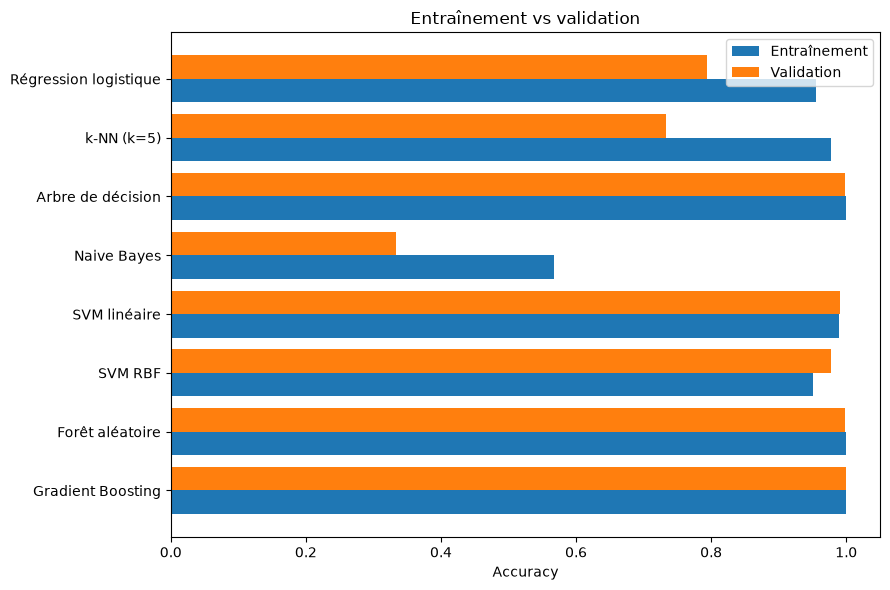

In [39]:
# 3.5 (suite) Entraînement vs validation : repérer le sur-apprentissage
ordre = bv.index[::-1]
pos = np.arange(len(ordre))

plt.figure(figsize=(9, 6))
plt.barh(pos - 0.2, bv.loc[ordre, 'Accuracy (train)'], height=0.4, label='Entraînement')
plt.barh(pos + 0.2, bv.loc[ordre, 'Accuracy (validation)'], height=0.4, label='Validation')
plt.yticks(pos, ordre)
plt.xlabel('Accuracy')
plt.title('Entraînement vs validation')
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
# 3.5 (suite) Modèle retenu : meilleur F1 de validation parmi les modèles « équilibrés »
candidats = bv[bv['Diagnostic'] == 'Équilibré'].index
if len(candidats) == 0:
    candidats = bv.index            # aucun modèle équilibré : on compare tous les modèles
meilleur = comparaison.loc[candidats, 'F1'].astype(float).idxmax()

print('Règle : F1 de validation le plus élevé parmi les modèles dont le diagnostic est « Équilibré »')
print('(accuracy d\'entraînement ≥ 0,80 et écart entraînement - validation ≤ 0,05).')
print(f'\nModèle retenu : {meilleur}')
print(comparaison.loc[meilleur].round(3).to_string())

Règle : F1 de validation le plus élevé parmi les modèles dont le diagnostic est « Équilibré »
(accuracy d'entraînement ≥ 0,80 et écart entraînement - validation ≤ 0,05).

Modèle retenu : Gradient Boosting
Accuracy     1.0
Précision    1.0
Rappel       1.0
F1           1.0
AUC          1.0


**Lecture du compromis biais / variance**
- **Biais élevé (sous-apprentissage)** : le modèle est trop simple, il se trompe déjà à l'entraînement (accuracy d'entraînement basse).
- **Variance élevée (sur-apprentissage)** : le modèle apprend l'entraînement par cœur et se dégrade sur des cycles nouveaux (grand écart entre entraînement et validation, et validation croisée instable).
- **Équilibré** : bons scores à l'entraînement et en validation, écart faible, validation croisée stable.

Les seuils (0,80 et 0,05) sont des repères fixés avant de voir les résultats, pas des valeurs ajustées. Les modèles sont optimisés à l'étape 4 ; le choix final s'y fait par validation croisée, puis le modèle choisi est évalué une seule fois sur le test final.

# 4. Optimisation des hyperparamètres

Les hyperparamètres sont optimisés **sur les 2 000 cycles de développement**, par validation croisée à 5 plis **par blocs de conditions** (les mêmes plis qu'en 3.5, pour éviter toute fuite). Le critère d'optimisation est le **F1-score** de la classe « optimale ». Le test final n'intervient pas.

## 4.1 Grid Search : recherche exhaustive sur une grille

In [41]:
# 4.1 Grid Search : recherche exhaustive (modèles à peu d'hyperparamètres)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

SCORING = 'f1'
recherches = {}      # nom -> (objet de recherche ajusté, méthode, nom du modèle avant optimisation)

grilles = {
    'Régression logistique': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
                              {'logisticregression__C': [0.01, 0.1, 1, 10, 100]},
                              'Régression logistique'),
    'k-NN': (make_pipeline(StandardScaler(), KNeighborsClassifier()),
             {'kneighborsclassifier__n_neighbors': [3, 5, 9, 15, 25],
              'kneighborsclassifier__weights': ['uniform', 'distance']},
             'k-NN (k=5)'),
    'Arbre de décision': (DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_STATE),
                          {'max_depth': [2, 3, 4, 5, 8], 'min_samples_leaf': [1, 5, 10, 20]},
                          'Arbre de décision'),
    'SVM RBF': (make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=RANDOM_STATE)),
                {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': ['scale', 0.01, 0.1, 1]},
                'SVM RBF'),
}

for nom, (modele, grille, nom_defaut) in grilles.items():
    gs = GridSearchCV(modele, grille, scoring=SCORING, cv=plis, n_jobs=-1, return_train_score=True)
    gs.fit(X_dev_sel, y_dev)
    recherches[nom] = (gs, 'Grid Search', nom_defaut)
    print(f'{nom:22s} meilleur F1 (CV) = {gs.best_score_:.3f} | {gs.best_params_}')

Régression logistique  meilleur F1 (CV) = 0.985 | {'logisticregression__C': 100}
k-NN                   meilleur F1 (CV) = 0.895 | {'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'distance'}
Arbre de décision      meilleur F1 (CV) = 0.993 | {'max_depth': 8, 'min_samples_leaf': 1}
SVM RBF                meilleur F1 (CV) = 0.999 | {'svc__C': 100, 'svc__gamma': 'scale'}


## 4.2 Random Search : recherche aléatoire

In [42]:
# 4.2 Random Search : recherche aléatoire (modèles d'ensemble, espace plus grand)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

distributions = {
    'Forêt aléatoire': (RandomForestClassifier(random_state=RANDOM_STATE),
                        {'n_estimators': randint(100, 400), 'max_depth': randint(3, 15),
                         'min_samples_leaf': randint(1, 15), 'max_features': ['sqrt', 'log2', 0.5]},
                        'Forêt aléatoire'),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE),
                          {'n_estimators': randint(50, 300), 'learning_rate': loguniform(0.01, 0.3),
                           'max_depth': randint(1, 5), 'subsample': uniform(0.6, 0.4)},
                          'Gradient Boosting'),
}

for nom, (modele, distrib, nom_defaut) in distributions.items():
    rs = RandomizedSearchCV(modele, distrib, n_iter=20, scoring=SCORING, cv=plis, n_jobs=-1,
                            random_state=RANDOM_STATE, return_train_score=True)
    rs.fit(X_dev_sel, y_dev)
    recherches[nom] = (rs, 'Random Search', nom_defaut)
    print(f'{nom:22s} meilleur F1 (CV) = {rs.best_score_:.3f} | {rs.best_params_}')

Forêt aléatoire        meilleur F1 (CV) = 0.999 | {'max_depth': 14, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 158}
Gradient Boosting      meilleur F1 (CV) = 0.995 | {'learning_rate': np.float64(0.04616803492122799), 'max_depth': 2, 'n_estimators': 239, 'subsample': np.float64(0.9706635463175177)}


## 4.3 Évaluation des modèles optimisés par validation croisée (k-fold)

In [43]:
# 4.3 Modèles optimisés : F1 en validation croisée par blocs, avant et après optimisation
# « Autres plis » : nouveaux plis (autre graine) pour une mesure moins favorable aux réglages choisis sur les premiers plis
plis_bis = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1).split(X_dev_sel, y_dev, groupes))

lignes = {}
for nom, (obj, methode, nom_defaut) in recherches.items():
    i = obj.best_index_
    avant = cross_val_score(modeles[nom_defaut], X_dev_sel, y_dev, cv=plis, scoring=SCORING)
    autres = cross_val_score(obj.best_estimator_, X_dev_sel, y_dev, cv=plis_bis, scoring=SCORING)
    lignes[nom] = {'Méthode': methode,
                   'F1 CV avant optimisation': avant.mean(),
                   'F1 CV après optimisation': obj.cv_results_['mean_test_score'][i],
                   'F1 CV écart-type': obj.cv_results_['std_test_score'][i],
                   'F1 train (CV)': obj.cv_results_['mean_train_score'][i],
                   'F1 CV (autres plis)': autres.mean()}
optim = pd.DataFrame(lignes).T
for c in optim.columns[1:]:
    optim[c] = optim[c].astype(float)
optim = optim.sort_values('F1 CV (autres plis)', ascending=False)
optim.round(3)

,Méthode,F1 CV avant optimisation,F1 CV après optimisation,F1 CV écart-type,F1 train (CV),F1 CV (autres plis)
SVM RBF,Grid Search,0.942,0.999,0.002,1.000,0.998
Forêt aléatoire,Random Search,0.998,0.999,0.001,1.000,0.997
Gradient Boosting,Random Search,0.994,0.995,0.005,1.000,0.991
Arbre de décision,Grid Search,0.993,0.993,0.005,1.000,0.988
Régression logistique,Grid Search,0.888,0.985,0.011,0.992,0.983
k-NN,Grid Search,0.887,0.895,0.070,1.000,0.887


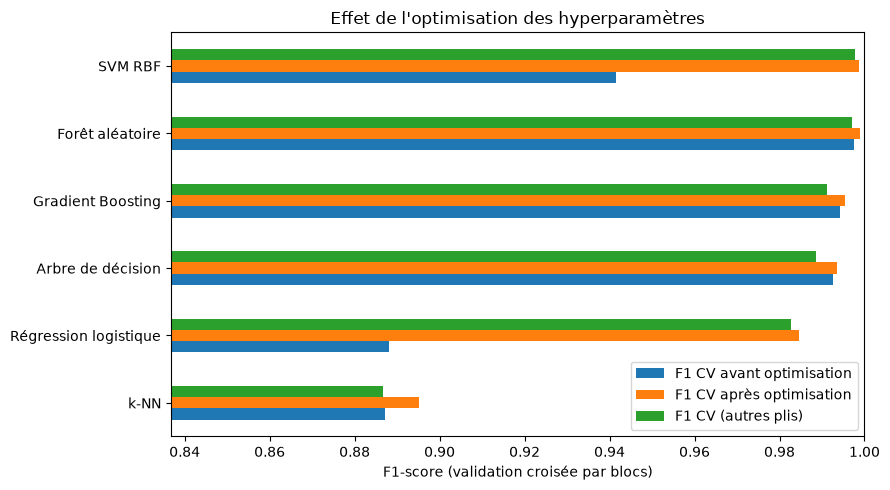

In [44]:
# 4.3 (suite) Comparaison avant / après optimisation
optim[['F1 CV avant optimisation', 'F1 CV après optimisation', 'F1 CV (autres plis)']].iloc[::-1].plot.barh(figsize=(9, 5))
plt.xlabel('F1-score (validation croisée par blocs)')
plt.title("Effet de l'optimisation des hyperparamètres")
plt.xlim(max(0, optim[['F1 CV avant optimisation', 'F1 CV après optimisation', 'F1 CV (autres plis)']].min().min() - 0.05), 1.0)
plt.tight_layout()
plt.show()

**Précaution de lecture.** Le meilleur score d'une recherche est le maximum obtenu sur de nombreux réglages : il est un peu optimiste. La colonne « autres plis » le mesure sur un découpage différent, ce qui réduit l'optimisme sans le supprimer. Seul le test final, jamais utilisé pour choisir, donne une mesure non biaisée.

## 4.4 Modèle final et évaluation sur le test final

In [45]:
# 4.4 Choix du modèle final (règle fixée à l'avance : meilleur F1 CV sur les autres plis), puis évaluation UNIQUE sur le test final
meilleur_final = optim.index[0]
final = recherches[meilleur_final][0].best_estimator_       # déjà ré-entraîné sur les 2000 cycles de développement
print('Modèle final :', meilleur_final)
print('Hyperparamètres :', recherches[meilleur_final][0].best_params_)

y_pred_test = final.predict(X_test_sel)
score_test = scores_modele(final, X_test_sel)
print('\n--- Test final (205 cycles, utilisé une seule fois) ---')
print(f'Accuracy  : {accuracy_score(y_test, y_pred_test):.3f}')
print(f'Précision : {precision_score(y_test, y_pred_test):.3f}')
print(f'Rappel    : {recall_score(y_test, y_pred_test):.3f}')
print(f'F1-score  : {f1_score(y_test, y_pred_test):.3f}')
print(f'AUC       : {roc_auc_score(y_test, score_test):.3f}')
print(f'\nPart de valves optimales : développement = {y_dev.mean():.3f} | test final = {y_test.mean():.3f}')

Modèle final : SVM RBF
Hyperparamètres : {'svc__C': 100, 'svc__gamma': 'scale'}

--- Test final (205 cycles, utilisé une seule fois) ---
Accuracy  : 1.000
Précision : 1.000
Rappel    : 1.000
F1-score  : 1.000
AUC       : 1.000

Part de valves optimales : développement = 0.526 | test final = 0.356


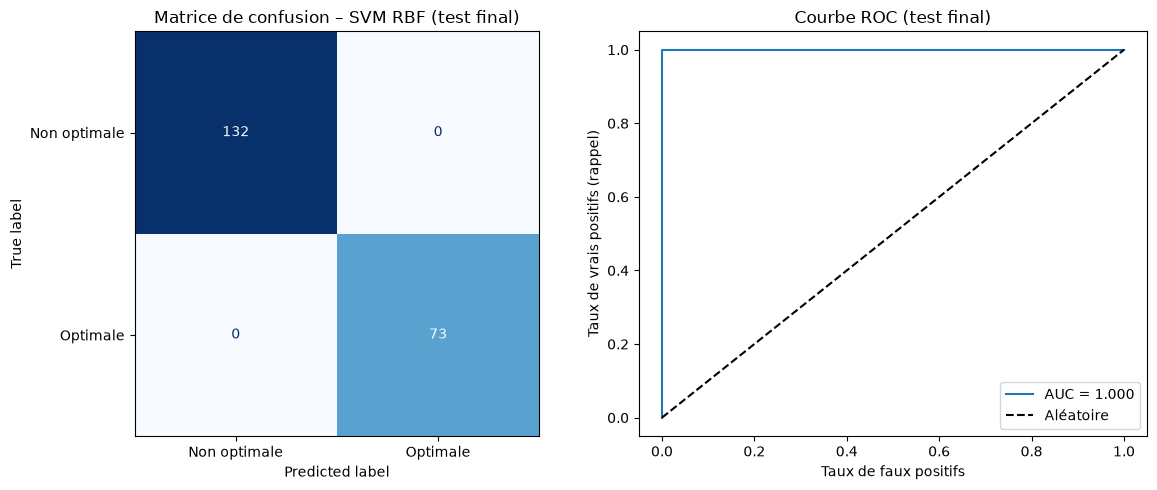

In [46]:
# 4.4 (suite) Matrice de confusion et courbe ROC sur le test final
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, display_labels=['Non optimale', 'Optimale'],
                                        cmap='Blues', colorbar=False, ax=axes[0])
axes[0].set_title(f'Matrice de confusion – {meilleur_final} (test final)')

fpr, tpr, _ = roc_curve(y_test, score_test)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, score_test):.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', label='Aléatoire')
axes[1].set_xlabel('Taux de faux positifs')
axes[1].set_ylabel('Taux de vrais positifs (rappel)')
axes[1].set_title('Courbe ROC (test final)')
axes[1].legend()
plt.tight_layout()
plt.show()

**Lecture du test final.** Le test final est la seule mesure non biaisée : il n'a servi ni à entraîner, ni à choisir les variables, ni à régler les hyperparamètres. Sa composition diffère du développement (part de valves optimales, conditions de fonctionnement), donc ses scores peuvent différer de ceux de la validation croisée : on compare surtout le F1-score et l'AUC. Un écart important entre la validation croisée et le test final signale un décalage de distribution, pas nécessairement un défaut du modèle.

In [47]:
# 4.5 Contrôles de cohérence (complément) : quelles variables portent le signal ?
print('Variables retenues :', list(X_dev_sel.columns))
print('Part de la classe majoritaire (référence) : %.3f' % max(y_dev.mean(), 1 - y_dev.mean()))
nb_plis = cross_val_score(modeles['Naive Bayes'], X_dev_sel, y_dev, cv=plis, scoring='accuracy')
print('Naive Bayes (toutes variables), accuracy par pli :', nb_plis.round(3))

lignes = {}
for col in X_dev_sel.columns:
    Xc = X_dev_sel[[col]]
    souche = cross_val_score(DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE), Xc, y_dev, cv=plis, scoring='accuracy')
    bayes = cross_val_score(make_pipeline(StandardScaler(), GaussianNB()), Xc, y_dev, cv=plis, scoring='accuracy')
    lignes[col] = {'Souche (1 seuil)': souche.mean(), 'Naive Bayes (variable seule)': bayes.mean()}
signal = pd.DataFrame(lignes).T.sort_values('Souche (1 seuil)', ascending=False)
signal.round(3)

Variables retenues : ['PS2_kurtosis', 'FS1_q75', 'PS2_mean', 'FS1_std', 'PS2_q25', 'PS2_median', 'FS1_max', 'FS1_kurtosis']
Part de la classe majoritaire (référence) : 0.526
Naive Bayes (toutes variables), accuracy par pli : [0.333 0.7   0.704 0.445 0.319]


,Souche (1 seuil),Naive Bayes (variable seule)
PS2_kurtosis,0.966,0.553
FS1_q75,0.743,0.510
FS1_std,0.634,0.553
PS2_q25,0.518,0.359
FS1_kurtosis,0.490,0.553
PS2_mean,0.468,0.553
PS2_median,0.421,0.558
FS1_max,0.328,0.422


In [48]:
# 4.5 (suite) Le modèle final sur chaque configuration du test final
from IPython.display import display
cfg = profile_test[['Cooler', 'Pump_leakage', 'Accumulator']].astype(str).agg('-'.join, axis=1).to_numpy()
tab = pd.DataFrame({'Configuration': cfg, 'Valve': profile_test['Valve'].to_numpy(),
                    'Correct': (y_pred_test == y_test.to_numpy())})
par_config = tab.groupby('Configuration').agg(Cycles=('Correct', 'size'), Accuracy=('Correct', 'mean'))
par_config['Vue en développement'] = par_config.index.isin(set(groupes))
par_valve = tab.groupby('Valve').agg(Cycles=('Correct', 'size'), Accuracy=('Correct', 'mean'))
display(par_config.round(3))
display(par_valve.round(3))

,Cycles,Accuracy,Vue en développement
Configuration,,,
100-0-100,41,1.0,True
100-0-90,60,1.0,True
100-1-100,22,1.0,True
100-1-90,41,1.0,False
100-2-90,41,1.0,False


,Cycles,Accuracy
Valve,,
73,40,1.0
80,42,1.0
90,50,1.0
100,73,1.0


        count  mean   std   min   25%   50%   75%   max
Valve                                                  
0       948.0  1.24  0.34  0.46  1.33  1.40  1.46  1.48
1      1052.0  1.45  0.23  0.57  1.50  1.51  1.52  1.52
Asymétrie (skew) par classe : {0: -1.59, 1: -3.59}


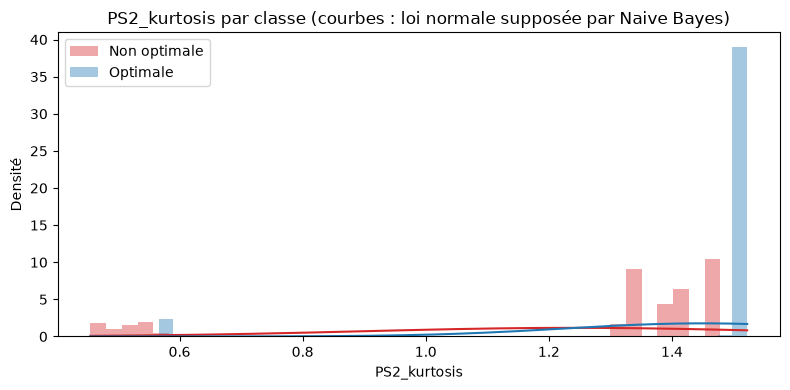

In [49]:
# 4.5 (suite) Pourquoi Naive Bayes échoue : forme de la meilleure variable, par classe
from scipy.stats import norm
v = 'PS2_kurtosis'
print(X_dev[v].groupby(y_dev).describe().round(2))
print('Asymétrie (skew) par classe :', X_dev[v].groupby(y_dev).skew().round(2).to_dict())

fig, ax = plt.subplots(figsize=(8, 4))
grille = np.linspace(X_dev[v].min(), X_dev[v].max(), 300)
for classe, couleur, nom in [(0, 'tab:red', 'Non optimale'), (1, 'tab:blue', 'Optimale')]:
    x = X_dev.loc[y_dev == classe, v]
    ax.hist(x, bins=40, density=True, alpha=0.4, color=couleur, label=nom)
    ax.plot(grille, norm.pdf(grille, x.mean(), x.std()), color=couleur)
ax.set_xlabel(v)
ax.set_ylabel('Densité')
ax.set_title('PS2_kurtosis par classe (courbes : loi normale supposée par Naive Bayes)')
ax.legend()
plt.tight_layout()
plt.show()

In [50]:
# 4.5 (suite) Que contient le petit groupe de faible kurtosis ? (interprétation uniquement)
bas = X_dev['PS2_kurtosis'] < 1.0
print(pd.crosstab(profile_dev['Cooler'], bas, margins=True))

PS2_kurtosis  False  True   All
Cooler                         
3               492   240   732
20              732     0   732
100             536     0   536
All            1760   240  2000


In [51]:
# 4.5 (suite) Où se concentrent les erreurs ? Accuracy par niveau du refroidisseur (prédictions hors-pli, blocs jamais vus)
from sklearn.model_selection import cross_val_predict

lignes = {}
for nom, m in modeles.items():
    pred = cross_val_predict(m, X_dev_sel, y_dev, cv=plis)
    correct = pd.Series(pred == y_dev.to_numpy(), index=y_dev.index)
    lignes[nom] = correct.groupby(profile_dev['Cooler']).mean()
par_cooler = pd.DataFrame(lignes).T
par_cooler.columns = [f'Cooler = {c} %' for c in par_cooler.columns]
par_cooler.round(3)

,Cooler = 3 %,Cooler = 20 %,Cooler = 100 %
Régression logistique,0.914,0.925,0.845
k-NN (k=5),0.881,0.981,0.782
Arbre de décision,0.978,1.000,1.000
Naive Bayes,0.675,0.508,0.319
SVM linéaire,0.973,0.985,1.000
SVM RBF,0.906,0.966,1.000
Forêt aléatoire,0.993,1.000,1.000
Gradient Boosting,0.984,1.000,0.998
